# Equation discovery on a heated rod

The test system is a rod of length one, held at zero temperature at both ends:

$$\frac{\partial T}{\partial t}=\alpha\,\frac{\partial^2 T}{\partial x^2}\;(+\,q(x)),\qquad x\in[0,1],\qquad
T(0,t)=T(1,t)=0,\qquad \alpha=0.1 .$$

The data are simulated: initial profiles are random sums of eight sine modes,
$a(x)=\sum_{k=1}^{8}c_k\sin(k\pi x)$ with $c_k\sim\mathcal N(0,1/k^2)$, marched to $t_{\mathrm f}=0.05$ with an explicit
finite-difference scheme (forward in time, centred in space; FTCS) on $128$ points. The rod and its solver live in the
shared benchmark library `pyutils/benchmarks/heat1d.py`. This notebook *rediscovers the equation* from the data:

* **Case A, the coefficient.** Space-time snapshots $T(x,t)$ of twenty training profiles; finite-difference
  derivatives; PDE-FIND on the library $\{1,T,T_x,T_{xx},T_{xxx},T^2,T\,T_x\}$ with STLSQ. Expected answer:
  $\partial_t T=0.1\,T_{xx}$ and nothing else.
* **Why one sine mode is not enough.** The same regression on a single-mode profile, where $T_{xx}=-\pi^2T$ and the
  diffusivity cannot be identified.
* **Case B, the missing source.** The rod now carries a heat source $q(x)=20\sin(2\pi x)$ that the modeller's equation
  omits. A modeller who knows $\alpha=0.1$ forms the residual $\partial_t T-\alpha T_{xx}$ from data and regresses it on
  a library of functions of $x$. A hybrid model would learn this missing term as a neural-network *correction*; here
  it becomes an *equation*.

Discovery returns an equation, so the test is a **simulation**: the recovered PDE is integrated with the same FTCS
scheme on ten unseen test profiles and compared with the truth by the relative $L^2$ error at $t_{\mathrm f}$. The noise
experiment at the end repeats case A with $1\%$ Gaussian noise on $T$: finite differences return the right form with a
diffusivity three times too small, a formula predicts by how much, and the **weak form** removes the error by never
differentiating the data.

The prose narrates the **default** run. Change the values below and *Run All*; every figure, table and saved result
follows. Checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
T_F = 0.05                       # horizon; equals heat1d.T_F so that the rod is the one of Modules 20, 22, 25, 26
N_SNAP = 26                      # snapshots per trajectory, at linspace(0, T_F, N_SNAP)
N_TRAIN, N_TEST = 20, 10         # profiles per role (no validation split: STLSQ has one knob, chosen on the fit)
SEED_TRAIN, SEED_TEST = 1, 3     # family seeds per role (disjoint draws, the seeds of Module 20)
Q_AMP = 20.0                     # case B: the reference also carries q(x) = Q_AMP sin(2 pi x)
NOISE = 0.01                     # relative noise level of the noise experiment (fraction of the field's RMS)
NOISE_SEED = 0
WEAK_WIN = (12, 6, 24, 11)       # weak form: x-windows, t-windows per trajectory, window widths in grid points (x, t)
NOISE_SWEEP = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1]   # noise levels of the sweep, three seeds each
BUMP_X0, BUMP_W = 0.35, 0.04     # out-of-family profile exp(-(x-x0)^2/(2 w^2)), as in Modules 20 and 25
TRIM_X, TRIM_T = 3, 1            # grid points dropped at each end in x and t (one-sided differences there)
SHOW = [0, 4, 7]                 # test profiles drawn in the validation figure
# --------------------------------------------------------------------------

DEFAULTS = dict(T_F=0.05, N_SNAP=26, N_TRAIN=20, N_TEST=10, SEED_TRAIN=1, SEED_TEST=3, Q_AMP=20.0, NOISE=0.01,
                NOISE_SEED=0, WEAK_WIN=(12, 6, 24, 11), NOISE_SWEEP=[0.0, 0.001, 0.003, 0.01, 0.03, 0.1], BUMP_X0=0.35, BUMP_W=0.04, TRIM_X=3, TRIM_T=1)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the rod, the data and the library

Everything about the rod is imported, not redefined. Each training profile is marched by `heat1d.ftcs` to
$t_{\mathrm f}$ and the march is sampled at $26$ equispaced times, so a trajectory is a $26\times128$ space-time
field. Time derivatives come from `np.gradient` along $t$, spatial derivatives from repeated `np.gradient` along
$x$. The rows of the design matrix $\boldsymbol{\Theta}$ are the interior space-time
points of all twenty trajectories; the first and last snapshots and three points at each wall are dropped, because
`np.gradient` is one-sided there.

In [2]:
import sys, os, json, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
from pyutils.benchmarks import heat1d

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data')); os.makedirs(DATA, exist_ok=True)

ALPHA, x = heat1d.ALPHA, heat1d.X; N_X = len(x); dx = x[1] - x[0]
times = np.linspace(0.0, T_F, N_SNAP)
N_STEPS, dt_ref = heat1d.steps(T_F)
assert abs(T_F - heat1d.T_F) < 1e-12, 'T_F must equal heat1d.T_F (the benchmark horizon)'
print(f'rod: alpha = {ALPHA}, {N_X} points, FTCS {N_STEPS} steps of dt = {dt_ref:.2e} to t_f = {T_F}; '
      f'snapshots every {times[1]:.3f} (= {round(times[1]/dt_ref)} steps); '
      f'FTCS vs analytic series: max rel L2 {heat1d.check_reference():.1e}')

C = {'train': heat1d.sample_family(N_TRAIN, SEED_TRAIN), 'test': heat1d.sample_family(N_TEST, SEED_TEST)}
U0 = {role: np.array([heat1d.profile(c, x) for c in Cr]) for role, Cr in C.items()}
U0['bump'] = np.exp(-(x - BUMP_X0)**2 / (2*BUMP_W**2))[None, :]

def trajectories(U, q=None):
    # (n, N_SNAP, N_X): the reference FTCS march of every profile, sampled at `times`
    return np.array([np.array(heat1d.ftcs(u, T_F, q=q, snapshots=times)[1]) for u in U])

F = {role: trajectories(U) for role, U in U0.items()}
print('training data: fields of shape', F['train'].shape, '(profiles, snapshots, grid points)')

TERMS = ['1', 'T', 'T_x', 'T_xx', 'T_xxx', 'T^2', 'T T_x']
TRIM = (slice(None), slice(TRIM_T, N_SNAP - TRIM_T), slice(TRIM_X, N_X - TRIM_X))

def derivatives(Fld):
    Ft = np.gradient(Fld, times, axis=1); Fx = np.gradient(Fld, x, axis=2)
    Fxx = np.gradient(Fx, x, axis=2); Fxxx = np.gradient(Fxx, x, axis=2)
    return Ft, Fx, Fxx, Fxxx

def library(Fld):
    # design matrix Theta (rows: interior space-time points of all trajectories) and the target T_t
    Ft, Fx, Fxx, Fxxx = derivatives(Fld)
    col = lambda A: A[TRIM].ravel()
    T = col(Fld)
    cols = {'1': np.ones_like(T), 'T': T, 'T_x': col(Fx), 'T_xx': col(Fxx), 'T_xxx': col(Fxxx),
            'T^2': T**2, 'T T_x': T*col(Fx)}
    return np.stack([cols[n] for n in TERMS], 1), col(Ft)

Theta, y = library(F['train'])
print('design matrix', Theta.shape, '  target T_t', y.shape)

rod: alpha = 0.1, 128 points, FTCS 202 steps of dt = 2.48e-04 to t_f = 0.05; snapshots every 0.002 (= 8 steps); FTCS vs analytic series: max rel L2 9.6e-04
training data: fields of shape (20, 26, 128) (profiles, snapshots, grid points)
design matrix (58560, 7)   target T_t (58560,)


### STLSQ and the threshold

The STLSQ of the vessel notebook: least squares on column-normalized $\boldsymbol{\Theta}$, then repeated
thresholding and refitting on the surviving columns. The one knob is the threshold $\lambda$, and it is chosen the
way the lecture describes: sweep $\lambda$, watch the number of active terms and the fit error, and take
the **sparsest model on the plateau**: among the thresholds whose fit error stays within a factor $1.5$ of the
dense least-squares fit, the fewest terms, and the middle of that range of $\lambda$. Columns and target are
normalized, so $\lambda$ is dimensionless and $\lambda=1$ is the size of the target itself. Beyond the plateau the
true term is pruned and the error jumps to one, so the choice is not delicate.

In [3]:
def stlsq(Theta, y, lam, n_iter=20):
    # columns and target normalized, so that lambda is a dimensionless threshold (1 = the size of the target)
    norm = np.linalg.norm(Theta, axis=0) + 1e-12; Tn = Theta/norm; ny = np.linalg.norm(y); yn = y/ny
    xi = np.linalg.lstsq(Tn, yn, rcond=None)[0]
    for _ in range(n_iter):
        small = np.abs(xi) < lam; xi[small] = 0; big = ~small
        if big.any(): xi[big] = np.linalg.lstsq(Tn[:, big], yn, rcond=None)[0]
    return xi*ny/norm

LAMS = np.logspace(-3, 1, 41)

def sweep(Theta, y):
    # (active terms, relative fit error) for every threshold of LAMS
    out = [(int((np.abs(xi) > 1e-12).sum()), float(np.linalg.norm(Theta @ xi - y)/np.linalg.norm(y)))
           for xi in (stlsq(Theta, y, lam) for lam in LAMS)]
    return np.array([o[0] for o in out]), np.array([o[1] for o in out])

def choose_threshold(Theta, y, slack=1.5):
    # the sparsest model on the plateau: among thresholds whose fit error stays within `slack` of the dense
    # least-squares fit (and keep at least one term), take the fewest terms, and the middle of that lambda range
    n_act, err = sweep(Theta, y)
    ok = np.where((err <= slack*err[0]) & (n_act >= 1))[0]
    best = ok[n_act[ok] == n_act[ok].min()]
    return float(np.exp(np.mean(np.log(LAMS[[best[0], best[-1]]])))), n_act, err

def report(xi, names, true):
    for n, v in zip(names, xi):
        tag = '' if abs(v) < 1e-12 else ('  <- true' if n in true else '  <- spurious')
        print(f'   {n:12s} {v:+.5f}{tag}')

t0 = time.perf_counter()
LAM_A, n_act_A, err_A = choose_threshold(Theta, y)
xi_A = stlsq(Theta, y, LAM_A)
T_REG_A = time.perf_counter() - t0
alpha_hat = float(xi_A[TERMS.index('T_xx')])
spurious_A = {n: float(v) for n, v in zip(TERMS, xi_A) if n != 'T_xx' and abs(v) > 1e-12}
print(f'threshold lambda = {LAM_A:.3g} (plateau: {n_act_A[0]} -> {int((np.abs(xi_A) > 1e-12).sum())} terms; '
      f'fit error dense {err_A[0]:.2e}, chosen {np.linalg.norm(Theta @ xi_A - y)/np.linalg.norm(y):.2e})')
print('DISCOVERED:  T_t =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(TERMS, xi_A) if abs(v) > 1e-12))
print(f'recovered alpha = {alpha_hat:.4f}  (true {ALPHA}; error {abs(alpha_hat - ALPHA)/ALPHA*100:.2f} %)')
print('spurious terms:', spurious_A if spurious_A else 'none')
report(xi_A, TERMS, {'T_xx'})
if AT_DEFAULTS:
    assert abs(alpha_hat - ALPHA) < 0.005 and not spurious_A

threshold lambda = 0.0501 (plateau: 2 -> 1 terms; fit error dense 2.24e-02, chosen 2.25e-02)
DISCOVERED:  T_t = +0.1009 T_xx
recovered alpha = 0.1009  (true 0.1; error 0.91 %)
spurious terms: none
   1            +0.00000
   T            +0.00000
   T_x          +0.00000
   T_xx         +0.10091  <- true
   T_xxx        +0.00000
   T^2          +0.00000
   T T_x        +0.00000


Dense least squares already puts almost everything on $T_{xx}$, but it also keeps a $+0.02\,T$ term: the doubled
`np.gradient` under-resolves the curvature of the high modes (a relative truncation error of order
$(k\pi\,\Delta x)^2/3$, $1.3\%$ for $k=8$), and the regression repairs that with the term that is proportional to
$T_{xx}$ mode by mode. The threshold removes it, and the one surviving coefficient is the diffusivity to within a
percent. The sweep below is the picture to keep in mind: a long plateau with one term, then a cliff.

In [4]:
print(' lambda    active   rel. fit error')
for lam, n, e in list(zip(LAMS, n_act_A, err_A))[::4]:
    print(f' {lam:8.3g}   {n:3d}      {e:.2e}')
print(f'chosen: lambda = {LAM_A:.3g}')

 lambda    active   rel. fit error
    0.001     2      2.24e-02
  0.00251     2      2.24e-02
  0.00631     1      2.25e-02
   0.0158     1      2.25e-02
   0.0398     1      2.25e-02
      0.1     1      2.25e-02
    0.251     1      2.25e-02
    0.631     1      2.25e-02
     1.58     0      1.00e+00
     3.98     0      1.00e+00
       10     0      1.00e+00
chosen: lambda = 0.0501


### Validation by simulation on ten unseen profiles

Discovery hands back an equation, so the test is to **run** it. `march` integrates $\partial_t T=\sum_j\xi_j\theta_j$
with the FTCS scheme of the reference: the same grid, the step count of `heat1d.steps` for the recovered diffusivity, the same three-point stencil for
$T_{xx}$ (the other derivatives, if any term needs them, by central differences). With only $T_{xx}$ active the
march *is* `heat1d.ftcs` with $\alpha=\hat\alpha$. The error is the relative $L^2$ norm at $t_{\mathrm f}$, on the
ten test profiles of seed $3$ and on the Gaussian bump that is not in the sine family. A correct equation does not
care about the family it was identified on, which is the extrapolation argument for discovery over black boxes.

In [5]:
def rhs_terms(u):
    T_x = np.gradient(u, dx)
    T_xx = np.zeros_like(u); T_xx[1:-1] = (u[:-2] - 2*u[1:-1] + u[2:])/dx**2
    T_xxx = np.gradient(T_xx, dx)
    return {'1': np.ones_like(u), 'T': u, 'T_x': T_x, 'T_xx': T_xx, 'T_xxx': T_xxx, 'T^2': u**2, 'T T_x': u*T_x}

def march(u0, xi, names, t_end=T_F, q=None):
    # FTCS march of the recovered equation T_t = sum_j xi_j theta_j(T) (+ q), same grid and step count as heat1d
    active = [(n, float(v)) for n, v in zip(names, xi) if abs(v) > 1e-12]
    a_xx = dict(active).get('T_xx', heat1d.ALPHA)          # the CFL step count of heat1d, for this diffusivity
    n, dt = heat1d.steps(t_end, alpha=max(a_xx, 1e-6))
    u = np.asarray(u0, float).copy(); u[0] = u[-1] = 0.0
    src = 0.0 if q is None else np.asarray(q)
    for _ in range(n):
        terms = rhs_terms(u)
        u = u + dt*(sum(v*terms[nm] for nm, v in active) + src)
        u[0] = u[-1] = 0.0
    return u

# sanity: with T_xx alone the march is heat1d.ftcs with the recovered alpha
assert np.allclose(march(U0['test'][0], xi_A, TERMS), heat1d.ftcs(U0['test'][0], T_F, alpha=alpha_hat))

pred_test = np.array([march(u, xi_A, TERMS) for u in U0['test']])
truth_test = F['test'][:, -1]
err_test = heat1d.relative_l2(pred_test, truth_test)
pred_bump = march(U0['bump'][0], xi_A, TERMS)
err_bump = float(heat1d.relative_l2(pred_bump, F['bump'][0, -1]))
print(f'test profiles ({N_TEST}, seed {SEED_TEST}): rel L2 at t_f  mean {err_test.mean():.2e}, '
      f'median {np.median(err_test):.2e}, max {err_test.max():.2e}')
print(f'Gaussian bump (out of family):             rel L2 at t_f  {err_bump:.2e}')

reps = 20; t0 = time.perf_counter()
for _ in range(reps): heat1d.ftcs(U0['test'][0], T_F, alpha=alpha_hat)
COST_MS = (time.perf_counter() - t0)/reps*1e3
print(f'one FTCS solve of the recovered equation: {COST_MS:.2f} ms')
if AT_DEFAULTS:
    assert err_test.max() < 0.02 and err_bump < 0.02

test profiles (10, seed 3): rel L2 at t_f  mean 2.02e-03, median 2.17e-03, max 3.60e-03
Gaussian bump (out of family):             rel L2 at t_f  3.36e-03
one FTCS solve of the recovered equation: 0.76 ms


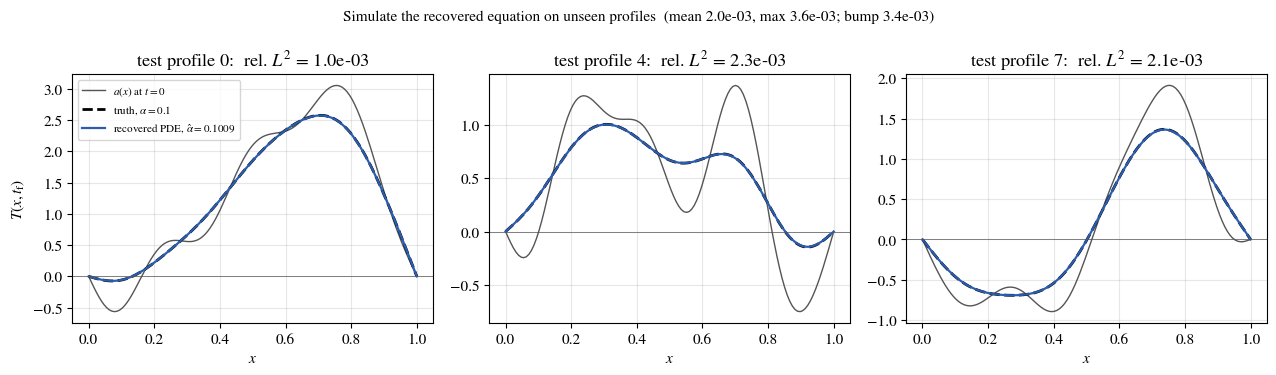

In [6]:
def plot_validation():
    fig, ax = plt.subplots(1, len(SHOW), figsize=(4.3*len(SHOW), 3.8), sharey=False)
    for a, i in zip(np.atleast_1d(ax), SHOW):
        a.plot(x, U0['test'][i], color=muted(), lw=1, label='$a(x)$ at $t=0$')
        a.plot(x, truth_test[i], '--', color=fg(), lw=2, label='truth, $\\alpha=0.1$')
        a.plot(x, pred_test[i], color='C0', lw=1.6, label=f'recovered PDE, $\\hat\\alpha={alpha_hat:.4f}$')
        a.axhline(0, color=muted(), lw=0.5)
        a.set(xlabel='$x$', title=f'test profile {i}:  rel. $L^2$ = {err_test[i]:.1e}')
        if i == SHOW[0]: a.set_ylabel('$T(x, t_{\\mathrm{f}})$'); a.legend(fontsize=8, loc='best')
    fig.suptitle(f'Simulate the recovered equation on unseen profiles  (mean {err_test.mean():.1e}, '
                 f'max {err_test.max():.1e}; bump {err_bump:.1e})', fontsize=11)
    plt.tight_layout()

save_dual(plot_validation, 'ed_heat_rod_validation', FIG)
plt.show()

### Why one sine mode is not enough

The training profiles are *sums* of eight modes for a reason. A single mode $T=\sin(\pi x)\,e^{-\alpha\pi^2 t}$ satisfies
$T_{xx}=-\pi^2T$ at every point and time, so the library columns $T$ and $T_{xx}$ are exactly proportional and any split
$\partial_tT=aT+bT_{xx}$ with $a-\pi^2b=-\alpha\pi^2$ fits perfectly: the diffusivity is not identifiable. The cell
compares one mode, two modes ($\sin\pi x+0.7\sin3\pi x$, which decay at different rates) and the eight-mode training
family: the condition number of the normalized $[T,\,T_{xx}]$ pair, and what STLSQ returns.

In [7]:
def identifiability(U_list):
    # condition number of the normalized [T, T_xx] columns, and the STLSQ equation, for trajectories from U_list
    Fs = np.array([np.array(heat1d.ftcs(u, T_F, snapshots=times)[1]) for u in U_list])
    Th, yy = library(Fs); Tn = Th/np.linalg.norm(Th, axis=0)
    cond = np.linalg.cond(Tn[:, [TERMS.index('T'), TERMS.index('T_xx')]])
    xi = stlsq(Th, yy, choose_threshold(Th, yy)[0])
    return float(cond), {n: float(v) for n, v in zip(TERMS, xi) if abs(v) > 1e-12}
ident = {'one mode': identifiability([np.sin(np.pi*x)]),
         'two modes': identifiability([np.sin(np.pi*x) + 0.7*np.sin(3*np.pi*x)]),
         f'{N_TRAIN} eight-mode profiles': identifiability(U0['train'])}
for lab, (cond, eq) in ident.items():
    print(f'{lab:22s} cond[T, T_xx] = {cond:9.2e}   T_t = ' + ' '.join(f'{v:+.4g} {n}' for n, v in eq.items()))
if AT_DEFAULTS:
    assert ident['one mode'][0] > 1e10 and abs(ident['two modes'][1].get('T_xx', 0) - ALPHA) < 0.002

one mode               cond[T, T_xx] =  1.92e+13   T_t = -60.55 T -4.289e+04 T_x -6.037 T_xx -4346 T_xxx
two modes              cond[T, T_xx] =  2.20e+00   T_t = +0.1003 T_xx
20 eight-mode profiles cond[T, T_xx] =  1.64e+00   T_t = +0.1009 T_xx


With one mode the pair is collinear to rounding (condition number $\sim10^{13}$) and the "discovered" equation is
nonsense; a second mode decaying at a different rate makes the pair well conditioned and $\alpha$ comes out right. The
data must *excite* every term that has to be told apart.

### Case B: the missing source, as an equation

Now the rod carries a source, $q(x)=20\sin(2\pi x)$, that the modeller's equation omits. A hybrid model would learn
the missing term as a neural-network correction --- something that can be plotted but not named. Here the modeller knows
$\alpha=0.1$, forms the residual $r=\partial_t T-\alpha T_{xx}$ at every interior space-time point of the training
trajectories, and regresses it on a library of functions of position,
$\{1,\sin\pi x,\sin2\pi x,\sin3\pi x,\sin4\pi x,x,x^2\}$. The residual of $20$ trajectories is not a single curve
but $58\,560$ noisy samples of one, which is exactly what least squares wants.

In [8]:
q_true = Q_AMP*np.sin(2*np.pi*x)
FQ = trajectories(U0['train'], q=q_true)
Ft, Fx, Fxx, Fxxx = derivatives(FQ)
r = (Ft - ALPHA*Fxx)[TRIM].ravel()
XX = np.broadcast_to(x, FQ.shape)[TRIM].ravel()
SRC_TERMS = ['1', 'sin(pi x)', 'sin(2pi x)', 'sin(3pi x)', 'sin(4pi x)', 'x', 'x^2']
def source_library(xx):
    cols = {'1': np.ones_like(xx), 'sin(pi x)': np.sin(np.pi*xx), 'sin(2pi x)': np.sin(2*np.pi*xx),
            'sin(3pi x)': np.sin(3*np.pi*xx), 'sin(4pi x)': np.sin(4*np.pi*xx), 'x': xx, 'x^2': xx**2}
    return np.stack([cols[n] for n in SRC_TERMS], 1)
Theta_B = source_library(XX)

t0 = time.perf_counter()
LAM_B, n_act_B, err_B = choose_threshold(Theta_B, r)
xi_B = stlsq(Theta_B, r, LAM_B)
T_REG_B = time.perf_counter() - t0
q_hat = float(xi_B[SRC_TERMS.index('sin(2pi x)')])
spurious_B = {n: float(v) for n, v in zip(SRC_TERMS, xi_B) if n != 'sin(2pi x)' and abs(v) > 1e-12}
print(f'threshold lambda = {LAM_B:.3g};  dense fit error {err_B[0]:.2e}')
print('DISCOVERED SOURCE:  q(x) =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(SRC_TERMS, xi_B) if abs(v) > 1e-12))
print(f'coefficient of sin(2 pi x) = {q_hat:.4f}  (true {Q_AMP}; error {abs(q_hat - Q_AMP)/Q_AMP*100:.3f} %)')
print('spurious terms:', spurious_B if spurious_B else 'none')
report(xi_B, SRC_TERMS, {'sin(2pi x)'})

# validation by simulation: known alpha plus the discovered source, on the test profiles of the forced rod
FQ_test = trajectories(U0['test'], q=q_true)
q_disc = source_library(x) @ xi_B
pred_B = np.array([heat1d.ftcs(u, T_F, q=q_disc) for u in U0['test']])
err_B_test = heat1d.relative_l2(pred_B, FQ_test[:, -1])
omit = heat1d.relative_l2(np.array([heat1d.ftcs(u, T_F) for u in U0['test']]), FQ_test[:, -1])
print(f'forced rod, test profiles: rel L2 at t_f with the discovered source  mean {err_B_test.mean():.2e}, '
      f'max {err_B_test.max():.2e};  source omitted (the modeller\'s equation)  median {np.median(omit):.2f}')
if AT_DEFAULTS:
    assert abs(q_hat - Q_AMP) < 0.1 and not spurious_B

threshold lambda = 0.0316;  dense fit error 2.25e-02
DISCOVERED SOURCE:  q(x) = +20.0155 sin(2pi x)
coefficient of sin(2 pi x) = 20.0155  (true 20.0; error 0.077 %)
spurious terms: none
   1            +0.00000
   sin(pi x)    +0.00000
   sin(2pi x)   +20.01545  <- true
   sin(3pi x)   +0.00000
   sin(4pi x)   +0.00000
   x            +0.00000
   x^2          +0.00000
forced rod, test profiles: rel L2 at t_f with the discovered source  mean 6.59e-04, max 2.28e-03;  source omitted (the modeller's equation)  median 0.65


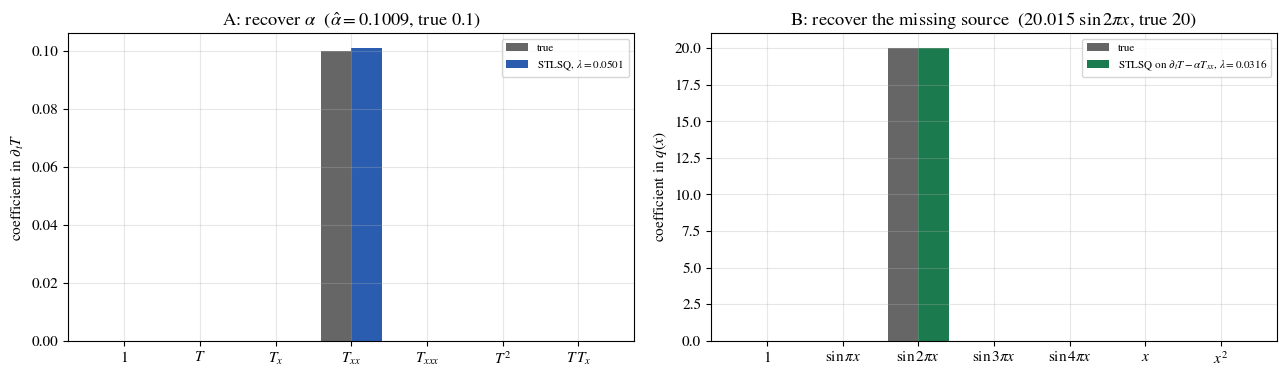

In [9]:
def plot_recovery():
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
    true_A = np.array([ALPHA if n == 'T_xx' else 0.0 for n in TERMS])
    pos = np.arange(len(TERMS))
    ax[0].bar(pos - 0.2, true_A, 0.4, label='true', color=fg(), alpha=0.6)
    ax[0].bar(pos + 0.2, xi_A, 0.4, label=f'STLSQ, $\\lambda={LAM_A:.3g}$', color='C0')
    ax[0].set_xticks(pos); ax[0].set_xticklabels(['$1$', '$T$', '$T_x$', '$T_{xx}$', '$T_{xxx}$', '$T^2$', '$T\\,T_x$'])
    ax[0].axhline(0, color=muted(), lw=0.6)
    ax[0].set(ylabel='coefficient in $\\partial_t T$', title=f'A: recover $\\alpha$  ($\\hat\\alpha={alpha_hat:.4f}$, true $0.1$)')
    ax[0].legend(fontsize=8)
    true_B = np.array([Q_AMP if n == 'sin(2pi x)' else 0.0 for n in SRC_TERMS])
    pos = np.arange(len(SRC_TERMS))
    ax[1].bar(pos - 0.2, true_B, 0.4, label='true', color=fg(), alpha=0.6)
    ax[1].bar(pos + 0.2, xi_B, 0.4, label=f'STLSQ on $\\partial_t T-\\alpha T_{{xx}}$, $\\lambda={LAM_B:.3g}$', color='C2')
    ax[1].set_xticks(pos)
    ax[1].set_xticklabels(['$1$', '$\\sin\\pi x$', '$\\sin2\\pi x$', '$\\sin3\\pi x$', '$\\sin4\\pi x$', '$x$', '$x^2$'])
    ax[1].axhline(0, color=muted(), lw=0.6)
    ax[1].set(ylabel='coefficient in $q(x)$', title=f'B: recover the missing source  ({q_hat:.3f} $\\sin 2\\pi x$, true $20$)')
    ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_recovery, 'ed_heat_rod_recovery', FIG)
plt.show()

### Noise: what finite differences do to case A

The same twenty trajectories with $1\%$ Gaussian noise on $T$ (one percent of the field's RMS), the same
derivatives, the same library, the same threshold rule. No smoothing, no weak form yet; this cell only reports
what happens.

In [10]:
rng = np.random.default_rng(NOISE_SEED)
sigma = NOISE*np.sqrt(np.mean(F['train']**2))
F_noisy = F['train'] + sigma*rng.standard_normal(F['train'].shape)
Theta_n, y_n = library(F_noisy)
LAM_N, n_act_N, err_N = choose_threshold(Theta_n, y_n)
xi_N = stlsq(Theta_n, y_n, LAM_N)
alpha_noisy = float(xi_N[TERMS.index('T_xx')])
spurious_N = {n: round(float(v), 4) for n, v in zip(TERMS, xi_N) if n != 'T_xx' and abs(v) > 1e-12}
_, _, Fxx_n, _ = derivatives(F_noisy); _, _, Fxx_c, _ = derivatives(F['train'])
snr_xx = np.linalg.norm(Fxx_c[TRIM])/np.linalg.norm((Fxx_n - Fxx_c)[TRIM])
Ft_n = np.gradient(F_noisy, times, axis=1); Ft_c = np.gradient(F['train'], times, axis=1)
snr_t = np.linalg.norm(Ft_c[TRIM])/np.linalg.norm((Ft_n - Ft_c)[TRIM])
print(f'noise sigma = {sigma:.2e} on T (RMS of T = {sigma/NOISE:.2f});  signal-to-noise after differencing: '
      f'T_t {snr_t:.2f}, T_xx {snr_xx:.2f}')
print(f'threshold lambda = {LAM_N:.3g}; dense fit error {err_N[0]:.2f} (clean: {err_A[0]:.2e})')
print('DISCOVERED (noisy):  T_t =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(TERMS, xi_N) if abs(v) > 1e-12))
print(f'recovered alpha with {NOISE*100:g} % noise = {alpha_noisy:.4f}  (true {ALPHA});  spurious terms: {spurious_N}')
# the dense fit and the single-term fit, to separate selection from attenuation
xi_dense_n = np.linalg.lstsq(Theta_n, y_n, rcond=None)[0]
print('dense least squares (noisy):  T_t =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(TERMS, xi_dense_n)))
j = TERMS.index('T_xx')
a_only = float(np.dot(Theta_n[:, j], y_n)/np.dot(Theta_n[:, j], Theta_n[:, j]))
print(f'least squares on the T_xx column alone: alpha = {a_only:.4f}  (errors-in-variables attenuation)')

noise sigma = 7.49e-03 on T (RMS of T = 0.75);  signal-to-noise after differencing: T_t 1.78, T_xx 0.64
threshold lambda = 0.316; dense fit error 0.83 (clean: 2.24e-02)
DISCOVERED (noisy):  T_t = +0.0290 T_xx
recovered alpha with 1 % noise = 0.0290  (true 0.1);  spurious terms: {}
dense least squares (noisy):  T_t = +0.3873 1 -2.4157 T -0.0025 T_x +0.0233 T_xx +0.0000 T_xxx -0.5742 T^2 +0.0071 T T_x
least squares on the T_xx column alone: alpha = 0.0290  (errors-in-variables attenuation)


One percent of noise on $T$ is amplified by $1/(4\,\Delta x^2)\approx4\times10^3$ in the doubled first-difference
$T_{xx}$ and by $1/(2\,\Delta t)=250$ in $T_t$, so the regressor $T_{xx}$ has a signal-to-noise ratio below one and
the target is not much better. The result is the textbook failure. The dense fit spreads the target over the smooth
columns $1$, $T$ and $T^2$, which carry no derivatives, and the threshold rule still finds the one-term model, but
with the wrong number: the $T_{xx}$ coefficient is $0.029$ instead of $0.1$. The single-column fit gives the same
value, so this is not a selection problem but a measurement problem: **errors in a regressor attenuate its
coefficient**. The *form* of the equation survives at this noise level; its *coefficient* does not, and nothing in the
data says which.

### The attenuation, predicted

For one regressor $\theta=\theta^\ast+n$ observed with noise $n$ that is uncorrelated with $\theta^\ast$ and with the
target noise, least squares returns
$$\hat\alpha=\frac{\langle\theta,y\rangle}{\langle\theta,\theta\rangle}\;\to\;
\alpha\,\frac{\|\theta^\ast\|^2}{\|\theta^\ast\|^2+\|n\|^2}=\alpha\,\frac{\mathrm{SNR}^2}{1+\mathrm{SNR}^2}.$$
Here the noise in $T_{xx}$ comes from the grid points $x\pm2\Delta x$ and $x$ of one snapshot and the noise in $T_t$
from the snapshots $t\pm\Delta t$ at one point, so the two are independent and the formula applies. The cell
below evaluates it with the *measured* signal-to-noise ratio of $T_{xx}$ (computed against the clean field, which the
notebook knows and a real modeller does not).

In [11]:
SNR = snr_xx
attenuation = SNR**2/(1 + SNR**2)
print(f'SNR of T_xx = {SNR:.3f}  ->  predicted alpha = {ALPHA} x {attenuation:.3f} = {ALPHA*attenuation:.4f};  '
      f'finite differences returned {alpha_noisy:.4f}')
if AT_DEFAULTS:
    assert abs(ALPHA*attenuation - alpha_noisy) < 0.002

SNR of T_xx = 0.635  ->  predicted alpha = 0.1 x 0.287 = 0.0287;  finite differences returned 0.0290


### The weak form on the rod

The remedy of the vessel notebook, now in space *and* time. Multiply $\partial_tT=\sum_j\xi_j\theta_j$ by a test
function $\varphi(x,t)=\varphi_x(x)\,\varphi_t(t)$ that vanishes, with its first derivatives, on the boundary of a
space--time window, integrate over the window, and move every derivative off the data by parts:
$$-\iint T\,\partial_t\varphi\;=\;\xi_{1}\!\iint\varphi+\xi_T\!\iint T\varphi-\xi_{T_x}\!\iint T\,\partial_x\varphi
+\xi_{T_{xx}}\!\iint T\,\partial_{xx}\varphi-\xi_{T_{xxx}}\!\iint T\,\partial_{xxx}\varphi+\xi_{T^2}\!\iint T^2\varphi
-\tfrac12\,\xi_{TT_x}\!\iint T^2\,\partial_x\varphi ,$$
using $T\,T_x=\tfrac12(T^2)_x$ for the last column. The bumps are $\varphi_x=((x-a)(b-x))^4$ on $24$-point windows
and $\varphi_t=((t-c)(d-t))^3$ on $11$-snapshot windows, so even $\partial_{xxx}\varphi$ vanishes at the window ends.
Twelve windows in $x$ times six in $t$ on each of the twenty trajectories give a $1440\times7$ system; the integrals
are trapezoidal sums of the raw samples. Same library, same STLSQ, same threshold rule.

In [12]:
trapz = getattr(np, 'trapezoid', None) or np.trapz      # numpy 2.x / 1.x

def bump(s, a, b, p):
    # phi = ((s-a)(b-s))^p on [a, b] and its first three derivatives, exact (polynomial)
    P = np.poly1d([-1, a + b, -a*b])**p
    return [P.deriv(k)(s) for k in range(4)]

def weak_system(Fld, win=WEAK_WIN):
    # one row per (trajectory, x-window, t-window); every derivative moved onto phi(x, t) = phi_x(x) phi_t(t)
    nwx, nwt, wx, wt = win
    xs = np.linspace(TRIM_X, N_X - 1 - TRIM_X - wx, nwx).astype(int); ts = np.linspace(0, N_SNAP - 1 - wt, nwt).astype(int)
    G, b = [], []
    for Fl in Fld:
        for i0 in xs:
            xx = x[i0:i0 + wx + 1]; px = bump(xx, xx[0], xx[-1], 4)
            for j0 in ts:
                tt = times[j0:j0 + wt + 1]; pt = bump(tt, tt[0], tt[-1], 3)
                T = Fl[j0:j0 + wt + 1, i0:i0 + wx + 1]
                I = lambda A, ft, fx: trapz(trapz(A*ft[:, None]*fx[None, :], xx, axis=1), tt)
                one = np.ones_like(T); nrm = I(one, pt[0], px[0])
                b.append(-I(T, pt[1], px[0])/nrm)
                G.append(np.array([I(one, pt[0], px[0]), I(T, pt[0], px[0]), -I(T, pt[0], px[1]), I(T, pt[0], px[2]),
                                   -I(T, pt[0], px[3]), I(T**2, pt[0], px[0]), -0.5*I(T**2, pt[0], px[1])])/nrm)
    return np.array(G), np.array(b)

t0 = time.perf_counter()
G_c, b_c = weak_system(F['train']); xi_W_clean = stlsq(G_c, b_c, choose_threshold(G_c, b_c)[0])
G_n, b_n = weak_system(F_noisy); LAM_W, _, _ = choose_threshold(G_n, b_n); xi_W = stlsq(G_n, b_n, LAM_W)
T_WEAK = (time.perf_counter() - t0)/2
alpha_weak = float(xi_W[TERMS.index('T_xx')])
spurious_W = {n: round(float(v), 4) for n, v in zip(TERMS, xi_W) if n != 'T_xx' and abs(v) > 1e-12}
print(f'weak system {G_n.shape}; build + fit {T_WEAK:.2f} s')
print('WEAK FORM (clean):  T_t =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(TERMS, xi_W_clean) if abs(v) > 1e-12))
print(f'WEAK FORM ({NOISE*100:g} % noise):  T_t =', ' '.join(f'{v:+.4f} {n}' for n, v in zip(TERMS, xi_W) if abs(v) > 1e-12),
      f'  spurious: {spurious_W if spurious_W else "none"}')
pred_W = np.array([heat1d.ftcs(u, T_F, alpha=alpha_weak) for u in U0['test']])
err_W = heat1d.relative_l2(pred_W, truth_test)
pred_FDn = np.array([heat1d.ftcs(u, T_F, alpha=alpha_noisy) for u in U0['test']])
err_FDn = heat1d.relative_l2(pred_FDn, truth_test)
print(f'simulated on the test profiles: rel L2 at t_f  weak form mean {err_W.mean():.2e};  '
      f'finite differences (alpha = {alpha_noisy:.3f}) mean {err_FDn.mean():.2e}')
if AT_DEFAULTS:
    assert abs(alpha_weak - ALPHA) < 0.002 and not spurious_W

weak system (1440, 7); build + fit 0.28 s
WEAK FORM (clean):  T_t = +0.1005 T_xx
WEAK FORM (1 % noise):  T_t = +0.1004 T_xx   spurious: none
simulated on the test profiles: rel L2 at t_f  weak form mean 9.12e-04;  finite differences (alpha = 0.029) mean 2.22e-01


### Noise sweep: finite differences, the attenuation formula and the weak form

The same experiment at six noise levels, three noise seeds each (medians). Finite differences follow the attenuation
formula until $T_{xx}$ is pruned altogether; the weak form holds the diffusivity.

 noise |  FD alpha predicted | weak alpha spurious   (true alpha = 0.1; medians of 3 seeds)
  0.0% |    0.1009    0.1000 |     0.1005        0
  0.1% |    0.0985    0.0976 |     0.1005        0
  0.3% |    0.0825    0.0818 |     0.1005        0
  1.0% |    0.0290    0.0287 |     0.1004        0
  3.0% |    0.0000    0.0043 |     0.1000        0
 10.0% |    0.0000    0.0004 |     0.0965        0


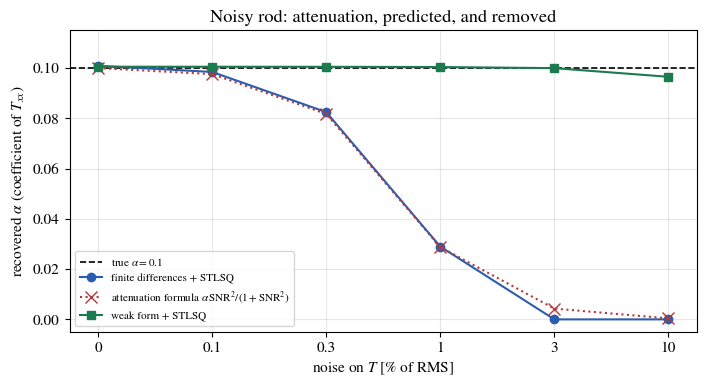

In [13]:
_, _, Fxx_clean, _ = derivatives(F['train'])
sweep_rows = []
for lev in NOISE_SWEEP:
    fd, pr, wk, wsp = [], [], [], []
    for s in range(3):
        rng_s = np.random.default_rng(s); sg = lev*np.sqrt(np.mean(F['train']**2))
        Fn = F['train'] + sg*rng_s.standard_normal(F['train'].shape)
        Th_s, y_s = library(Fn); fd.append(stlsq(Th_s, y_s, choose_threshold(Th_s, y_s)[0])[TERMS.index('T_xx')])
        _, _, Fxx_s, _ = derivatives(Fn)
        s2 = (np.linalg.norm(Fxx_clean[TRIM])/max(np.linalg.norm((Fxx_s - Fxx_clean)[TRIM]), 1e-30))**2
        pr.append(ALPHA*s2/(1 + s2))
        Gs, bs = weak_system(Fn); xw = stlsq(Gs, bs, choose_threshold(Gs, bs)[0])
        wk.append(xw[TERMS.index('T_xx')]); wsp.append(int(sum(abs(v) > 1e-12 for n, v in zip(TERMS, xw) if n != 'T_xx')))
    sweep_rows.append((lev, float(np.median(fd)), float(np.median(pr)), float(np.median(wk)), int(max(wsp))))
print(f'{"noise":>6} | {"FD alpha":>9} {"predicted":>9} | {"weak alpha":>10} {"spurious":>8}   (true alpha = {ALPHA}; medians of 3 seeds)')
for lev, a_fd, a_pr, a_wk, nsp in sweep_rows:
    print(f'{lev*100:5.1f}% | {a_fd:9.4f} {a_pr:9.4f} | {a_wk:10.4f} {nsp:8d}')

def plot_noise():
    lv = np.array([r[0] for r in sweep_rows]); xs = np.arange(len(lv))
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    ax.axhline(ALPHA, color=fg(), ls='--', lw=1.2, label='true $\\alpha=0.1$')
    ax.plot(xs, [r[1] for r in sweep_rows], 'o-', color='C0', label='finite differences + STLSQ')
    ax.plot(xs, [r[2] for r in sweep_rows], 'x:', color='C3', ms=9, label='attenuation formula $\\alpha\\,\\mathrm{SNR}^2/(1+\\mathrm{SNR}^2)$')
    ax.plot(xs, [r[3] for r in sweep_rows], 's-', color='C2', label='weak form + STLSQ')
    ax.set_xticks(xs); ax.set_xticklabels([f'{l*100:g}' for l in lv])
    ax.set(xlabel='noise on $T$ [% of RMS]', ylabel='recovered $\\alpha$ (coefficient of $T_{xx}$)',
           title='Noisy rod: attenuation, predicted, and removed', ylim=(-0.005, 0.115))
    ax.legend(fontsize=8, loc='lower left'); plt.tight_layout()

save_dual(plot_noise, 'ed_heat_rod_noise', FIG)
plt.show()
if AT_DEFAULTS:
    assert all(abs(r[3] - ALPHA) < 0.005 for r in sweep_rows if r[0] <= 0.03)

The prediction tracks the finite-difference coefficient at every level where $T_{xx}$ survives, so the failure is
fully explained: it is not the regression, it is the regressor. The weak form keeps the one-term heat equation and its
diffusivity to half a percent up to $3\%$ noise and to a few percent at $10\%$, at the cost of choosing a window. On
this rod, the honest answer at $1\%$ noise is a heat equation with $\hat\alpha=0.029$ by finite differences and
$\hat\alpha=0.100$ by the weak form.

In [14]:
notes = (f'Canonical rod of heat1d: alpha = {ALPHA}, {N_X} points, FTCS to t_f = {T_F}, {N_SNAP} snapshots per '
         f'trajectory; {N_TRAIN} training profiles (seed {SEED_TRAIN}), {N_TEST} test profiles (seed {SEED_TEST}); '
         f'no validation split (the single threshold is chosen on the fit-error plateau). '
         f'Case A: np.gradient derivatives, library {TERMS}, STLSQ lambda = {LAM_A:.3g}; '
         f'recovered T_t = {alpha_hat:.4f} T_xx with no spurious term; the recovered PDE is marched by the same FTCS '
         f'scheme on the test profiles. Case B: reference with q(x) = {Q_AMP:g} sin(2 pi x); residual '
         f'T_t - 0.1 T_xx regressed on {SRC_TERMS} with lambda = {LAM_B:.3g}; recovered {q_hat:.4f} sin(2 pi x), '
         f'no spurious term; marching alpha = 0.1 plus the discovered source gives test rel L2 mean '
         f'{err_B_test.mean():.2e} (source omitted: median {np.median(omit):.2f}). '
         f'Noise: {NOISE*100:g} % Gaussian noise on T, finite differences, same rule: alpha = {alpha_noisy:.4f}, '
         f'spurious {spurious_N} (the form survives, the coefficient is attenuated by SNR^2/(1+SNR^2) = {attenuation:.3f}); weak form (space-time bumps, {G_n.shape[0]} rows): alpha = {alpha_weak:.4f}, no spurious term. '
         f'Costs: one FTCS solve of the recovered equation, measured; train_time_s is the case-A regression '
         f'(library + threshold sweep + fit).')

results = {
    'method': 'Equation discovery (Module 21)', 'module': '21', 'rod': 'heat1d canonical',
    'what_is_learned': 'the PDE coefficients (alpha) and the missing source q(x)',
    'training_signal': 'data plus a candidate library',
    'physics_needed': 'the library of candidate terms',
    'solved_examples_for_training': N_TRAIN, 'n_train': N_TRAIN, 'n_val': 0, 'n_test': N_TEST,
    'test_rel_l2_mean': float(err_test.mean()), 'test_rel_l2_median': float(np.median(err_test)),
    'test_rel_l2_max': float(err_test.max()), 'bump_rel_l2': err_bump,
    'linear_baseline_rel_l2': None,
    'cost_per_case_ms_batched': COST_MS, 'cost_per_case_ms_single': COST_MS,
    'solver_per_case_ms_loop': COST_MS, 'solver_per_case_ms_vectorized': None,
    'train_time_s': T_REG_A,
    'alpha_recovered': alpha_hat, 'source_coefficient_recovered': q_hat,
    'alpha_recovered_1pct_noise': alpha_noisy,
    'alpha_recovered_1pct_noise_weak': alpha_weak,
    'notes': notes,
}
with open(os.path.join(DATA, 'heat_rod_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print(json.dumps({k: v for k, v in results.items() if k != 'notes'}, indent=1))

{
 "method": "Equation discovery (Module 21)",
 "module": "21",
 "rod": "heat1d canonical",
 "what_is_learned": "the PDE coefficients (alpha) and the missing source q(x)",
 "training_signal": "data plus a candidate library",
 "physics_needed": "the library of candidate terms",
 "solved_examples_for_training": 20,
 "n_train": 20,
 "n_val": 0,
 "n_test": 10,
 "test_rel_l2_mean": 0.00201777700347047,
 "test_rel_l2_median": 0.00216507638062686,
 "test_rel_l2_max": 0.003597485203095565,
 "bump_rel_l2": 0.0033623358074449435,
 "linear_baseline_rel_l2": null,
 "cost_per_case_ms_batched": 0.756418751552701,
 "cost_per_case_ms_single": 0.756418751552701,
 "solver_per_case_ms_loop": 0.756418751552701,
 "solver_per_case_ms_vectorized": null,
 "train_time_s": 0.3493411671370268,
 "alpha_recovered": 0.10090716854294544,
 "source_coefficient_recovered": 20.0154501621479,
 "alpha_recovered_1pct_noise": 0.028951994033405152,
 "alpha_recovered_1pct_noise_weak": 0.10040919000394424
}


**Takeaways.** On the heated rod, PDE-FIND with finite differences and STLSQ returns the heat equation with
its diffusivity to within a percent and nothing else; simulating that equation on unseen profiles, and on a
profile outside the training family, reproduces the truth to the same percent, because what was learned is the
equation and not the data. With the diffusivity known, the residual of the data against the model regressed on a
positional library names the missing source as $20\sin 2\pi x$: a correction a hybrid model would learn as a network
is here an equation. The data must also be rich enough: a single sine mode makes $T$ and $T_{xx}$ collinear and the
diffusivity unidentifiable. The finite-difference route breaks at one percent noise in a predictable way, attenuating the diffusivity by
$\mathrm{SNR}^2/(1+\mathrm{SNR}^2)$, and the weak form, which never differentiates the data, removes the error: $0.100$
again at one percent, within four percent of the truth at ten.